## [LAB-07] 추론통계

### 04-1_일원분산분석

### #01 준비작업

#### 1. 패키지 설치

- pingouin 패키지와 statsmodels 패키지의 설치가 필요하다.

In [2]:
!pip install --upgrade pingouin

In [3]:
!pip install --upgrade statsmodels

#### 2. 라이브러리 참조

In [4]:
from jussam import load_data
from helpers import *
from pandas import pivot_table

# 분산분석을 위한 라이브러리
from scipy.stats import f_oneway
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from pingouin import anova
from pingouin import welch_anova

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 3. 데이터 가져오기

- tree_weight 데이터셋은 소나무 품종별 무게를 조사한 데이터이다. 소나무 품종별로 평균 무게에 차이가 있는지 분석하라.

In [5]:
origin = load_data("tree_weight")
origin

📚 소나무 품종별 무게를 조사한 데이터 (출처: 방송통신대학교 통계학개론)


,weight,group
0,4.170,A
1,5.580,A
2,5.180,A
3,6.110,A
4,4.500,A
5,4.610,A
6,5.170,A
7,4.530,A
8,5.330,A
9,5.140,A


### #02 데이터 분포 및 가정 확인

#### 1. 데이터 분포

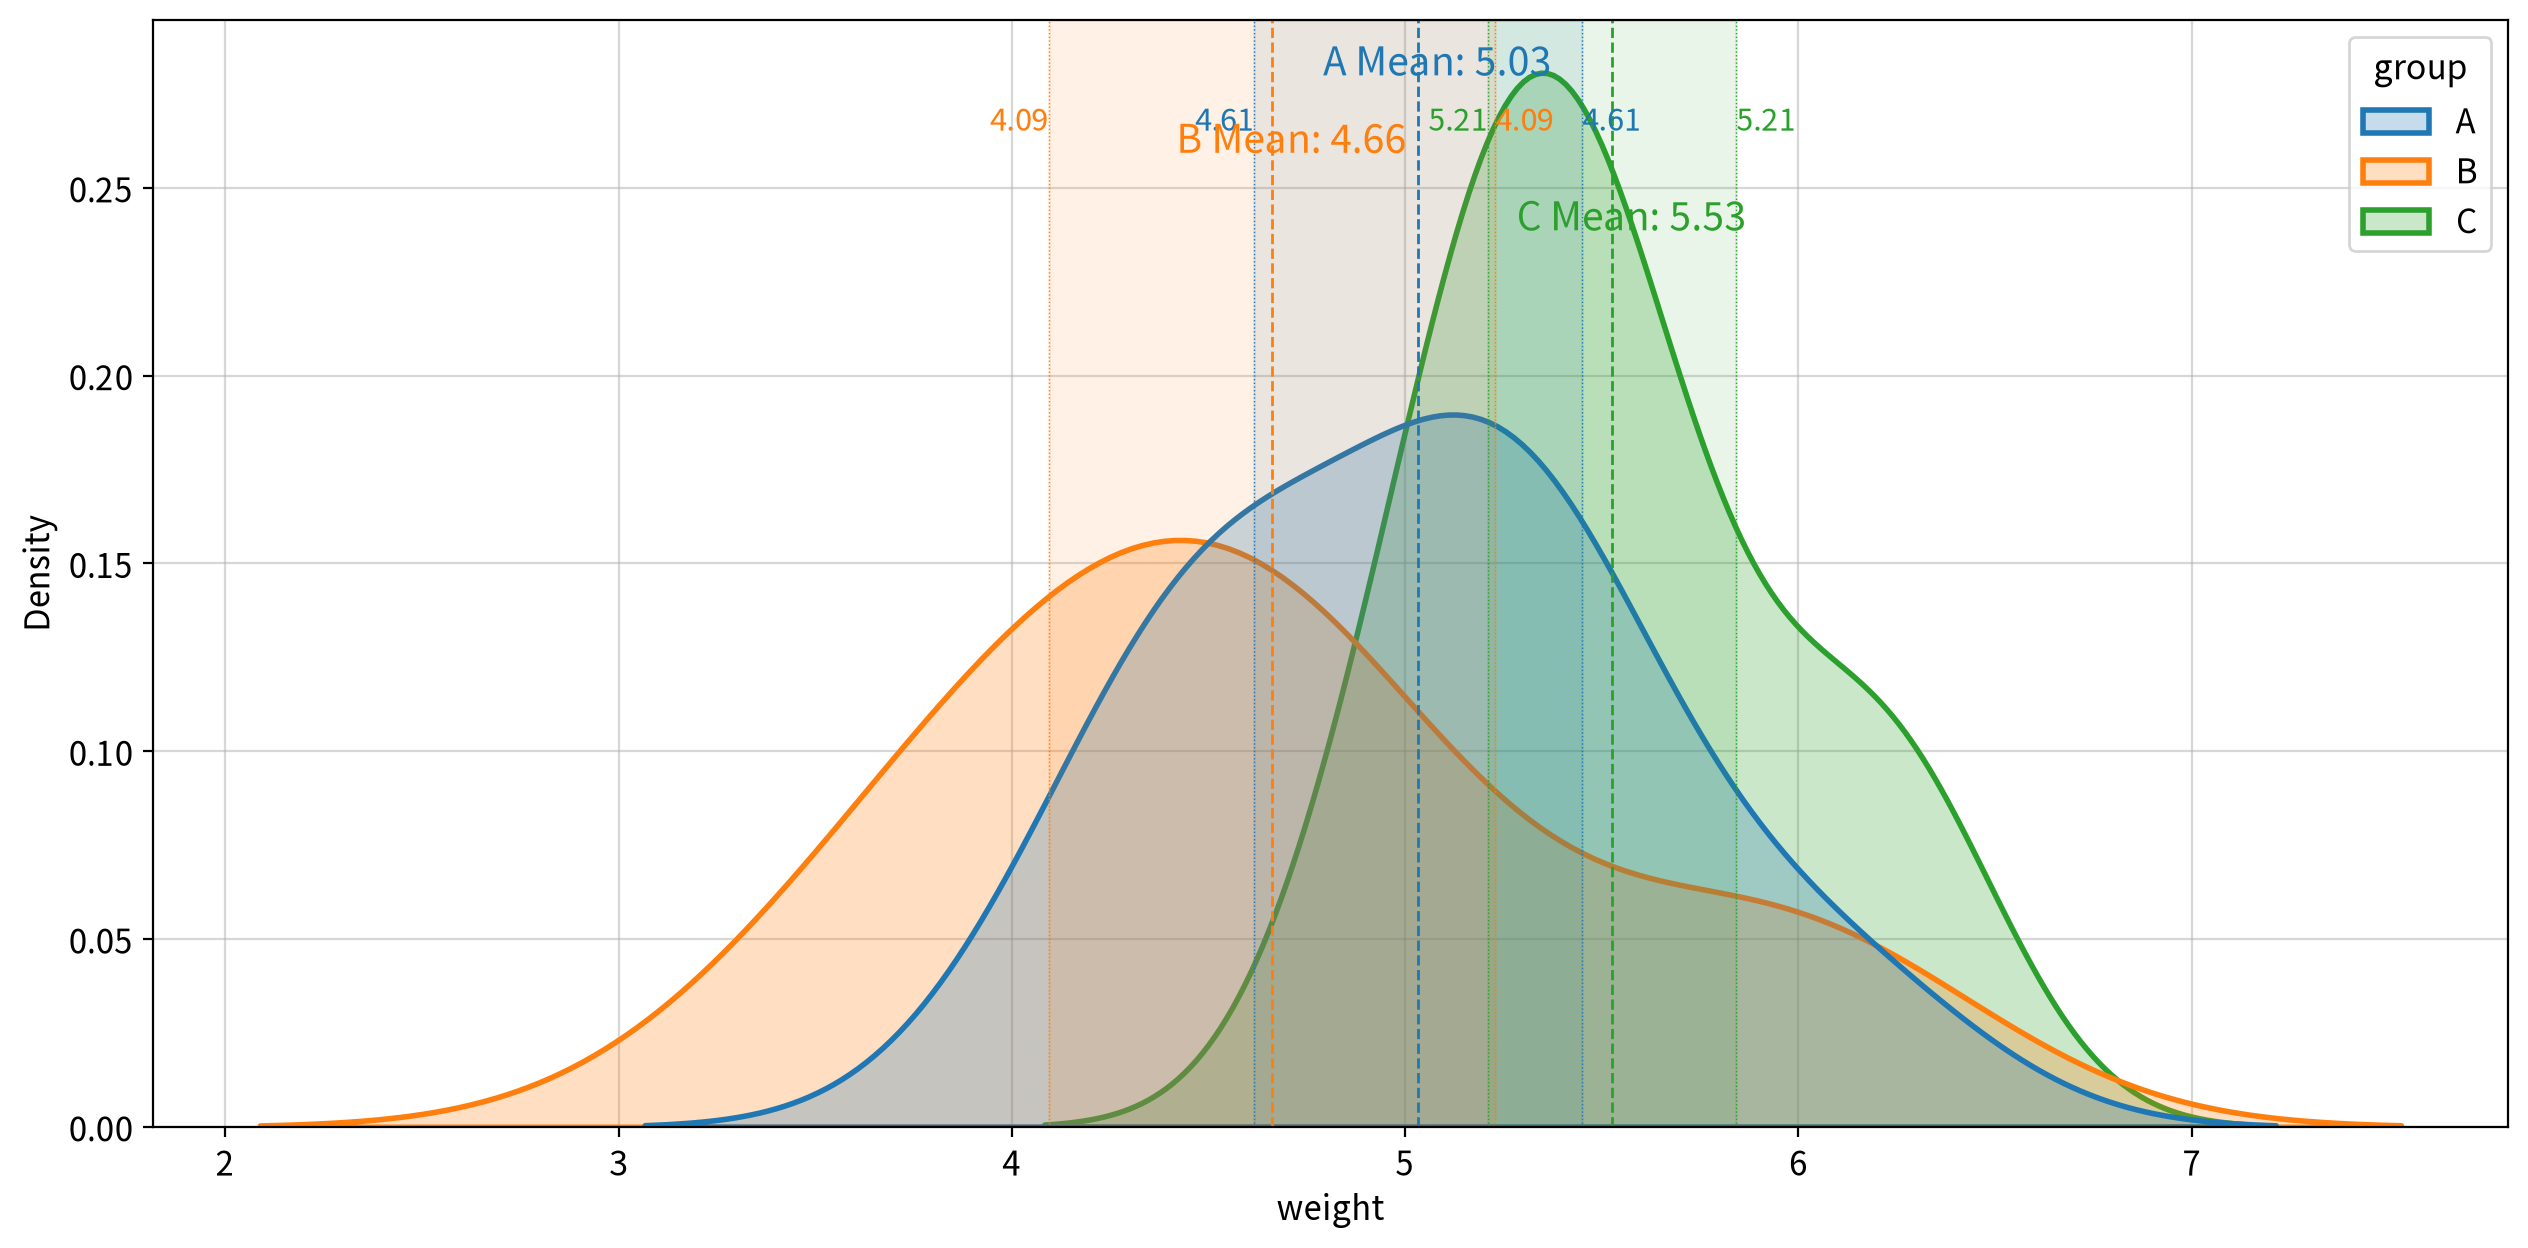

In [6]:
my_plot.kdeplot(origin, x='weight', hue='group', fill=True,
                meanline=True, clevel=0.95)

> 인사이트
> - **분산분석의 동기:** 평균이 B(4.66) < A(5.03) < C(5.53)로 벌어져 있어 집단 간 변동을 검정할 가치가 있음
> - **정규성 가정:** 세 분포가 종 모양 대칭 → normaltest로 확인
> - **등분산성 가정:** 분포 폭이 비슷 → Bartlett로 확인, 위반 시 Welch-ANOVA
> - **겹침:** 분포가 많이 겹쳐 눈으로 단정 불가, F·p로 판단 필요
> - **사후검정 예고:** B와 C는 신뢰수준 영역이 거의 안 겹치나 A는 애매 → 어느 쌍이 다른지는 사후검정 필요

#### 2. long 타입 데이터로 변환

In [7]:
df_wide = my_prep.long2wide(origin, hue='group', values='weight')
df_wide

,A,B,C
0,4.170,4.810,6.310
1,5.580,4.170,5.120
2,5.180,4.410,5.540
3,6.110,3.590,5.500
4,4.500,5.870,5.370
5,4.610,3.830,5.290
6,5.170,6.030,4.920
7,4.530,4.890,6.150
8,5.330,4.320,5.800
9,5.140,4.690,5.260


#### 3. 가설검정의 가정 확인

In [8]:
my_stats.test_assumptions(df_wide)

,test,statistic,p-value,result
field,,,,
A,normaltest,0.233,0.890,True
B,normaltest,0.968,0.616,True
C,normaltest,1.013,0.603,True
Bartlett,equal_var,2.879,0.237,True


> 정규성과 등분산성을 모두 충족한다.

### #03 일원분산분석

#### 1. Scipy 패키지를 사용하는 경우

- wide 타입의 데이터프레임을 사용해야 한다.
- 등분산성을 만족하지 않을 경우 equal_var = False 파라미터를 함께 설정하여 Welch-ANOVA로 전환한다.

    | 구분                       | 수식                                  | 내용                              |
    | ------------------------ | ----------------------------------- | ------------------------------- |
    | **귀무가설 (**\\(H_0\\)**)** | \\(\mu(A)=\mu(B)=\mu(C)\\)          | 세 품종 간의 평균 무게는 차이가 없다.          |
    | **대립가설 (**\\(H_1\\)**)** | Not all population means are equal. | 적어도 한 품종의 평균 무게는 다른 품종과 차이가 있다. |

In [9]:
s, p = f_oneway(df_wide['A'], df_wide['B'], df_wide['C'],
                equal_var=True)
"statistic: {0:.3f}, p-value: {1:.3f}".format(s, p)

'statistic: 4.846, p-value: 0.016'

> 세 종류의 소나무 품종의 평균 무게에 대해 분산분석을 수행한 결과 귀무가설을 기각하고 대립가설을 채택한다. (p < 0.05)   
> 즉, 세 종류의 소나무 품종 중에서 적어도 한 품종 이상은 평균 무게가 다르다.

#### 2. statsmodels 패키지를 사용하는 경우

- long 타입의 데이터프레임을 사용해야 한다.
- 데이터가 등분산성을 만족하지 않을 경우 anova_lm() 함수에 robust='hc3' 파라미터를 전달하여 Huber-White 추정치를 사용한다.
    - 원래는 Welch-ANOVA로 검정해야 하지만 statsmodels 패키지는 Welch-ANOVA를 지원하지 않고, Welch-ANOVA의 근사치를 제공하는 Robust ANOVA를 사용한다.
    - 그래서 statsmodels를 사용한 분산분석은 추천하지 않는다.

In [10]:
# 연속형변수이름 ~ C(그룹변수이름)
lm = ols('weight ~ C(group)', data=origin).fit()
anova_result = anova_lm(lm)
anova_result

,df,sum_sq,mean_sq,F,PR(>F)
C(group),2.000,3.766,1.883,4.846,0.016
Residual,27.000,10.492,0.389,NaN,NaN


**행: 변동의 원천**

| 구분           | 의미                                                                      |
| ------------ | ----------------------------------------------------------------------- |
| **C(group)** | 요인(처리)에 의한 변동, 즉 집단 간(between-group) 변동.<br>C()는 group을 범주형으로 처리하라는 의미. |
| **Residual** | 요인으로 설명되지 않는 잔차(집단 내, within-group) 변동. 즉 우연(오차)에 의한 변동.                |

**열: 각 변동에 대한 통계량**

| 구분          | 수식                       | 내용                                                                                           |
| ----------- | ------------------------ | -------------------------------------------------------------------------------------------- |
| **df**      | Degrees of Freedom (자유도) | 해당 변동(source)을 계산하기 위해 사용된 독립적인 정보의 수.<br>요인은 집단 수 − 1, 잔차는 전체 관측치 − 집단 수                    |
| **sum_sq**  | Sum of Squares (제곱합)     | 변동의 총량. 요인에 의한 변동(집단 간) 또는 잔차(집단 내) 변동을 수치로 표현                                               |
| **mean_sq** | Mean Square (제곱평균)       | 제곱합을 자유도로 나눈 값(sum_sq / df).<br>ANOVA의 계산 기반이 되는 분산 성분                                       |
| **F**       | F-statistic (F 통계량)      | 요인 mean_sq / 잔차 mean_sq.<br>요인에 의한 평균적인 변동 크기가 우연에 의한 변동보다 얼마나 큰지를 나타냄.<br>값이 클수록 집단 간 차이가 큼 |
| **PR(>F)**  | p-value (유의확률)           | 관찰된 F통계량 이상이 우연히 나올 확률.<br>매우 작으면 요인이 결과변수에 미치는 영향이 통계적으로 유의함을 의미.                           |

**ANOVA 결과표 해석**

**(1) 자유도(df)로 본 데이터 구조**

- 요인 자유도 2 → 집단 수는 2 + 1 = 3개 (품종 A, B, C)
- 잔차 자유도 27 → 전체 관측치는 27 + 3 = 30개

**(2) F 통계량**

- 집단 간 평균적인 변동 크기가 집단 내 변동보다 약 4.846배 크다.
- F = 집단 간 변동 / 집단 내 변동
- F = 1.883 / 0.389 ≈ 4.846
- F 값이 크다 = 품종 차이로 생긴 변동이 우연으로 생긴 변동보다 훨씬 크다는 신호.

**(3) p-value (PR(>F))**

- PR(>F) = 0.016 < 0.05
- 유의수준 0.05보다 작으므로 귀무가설 기각, 대립가설 채택

> 소나무 품종(group)에 따른 무게(weight)의 평균 차이에 대해 일원분산분석을 수행한 결과,
> F(2, 27) = 4.846, p = 0.016 < 0.05로 나타났다.
> 즉, 세 품종(A, B, C) 중 적어도 한 품종의 평균 무게는 다른 품종과 통계적으로 유의하게 다르다.

**한계:** 분산분석은 "어느 한 곳 이상에서 차이가 있다"는 것만 알려줄 뿐, 구체적으로 어떤 품종 간에 차이가 있는지는 알려주지 않는다.   
따라서 **사후검정(post hoc)**이 필요하다. (예: Tukey HSD, Bonferroni 등)

#### 3. pingouin 패키지 사용

(1) 등분산성을 충족하는 경우
- long 타입의 데이터 프레임을 사용해야 한다.

In [11]:
anova_result = anova(data=origin, dv='weight', between='group')
anova_result

,Source,ddof1,ddof2,F,p_unc,np2
0,group,2,27,4.846,0.016,0.264


(2) 등분산성을 충족하지 않는 경우
- 데이터가 등분산성을 만족하지 않을 경우 anova() 함수 대신 pingouin 패키지에 있는 welch_anova() 함수를 사용한다.
    - 이 예제는 등분산성을 충족하는 데이터지만 코드를 소개하기 위해 사용함

In [12]:
welch_anova(data=origin, dv='weight', between='group')

,Source,ddof1,ddof2,F,p_unc,np2
0,group,2,17.128,5.181,0.017,0.264


#### 결과표 해석
| 컬럼명        | 전체 이름                              | 의미 설명                                                                                               |
| ---------- | ---------------------------------- | --------------------------------------------------------------------------------------------------- |
| **Source** | 변동의 원천(요인)                         | 분석에 사용된 요인(독립변수)의 이름. 여기서는 group(품종).                                                               |
| **ddof1**  | 분자 자유도 (between-group df)          | 집단 간 변동의 자유도. 집단 수 − 1.<br>F 분포의 첫 번째 자유도.                                                          |
| **ddof2**  | 분모 자유도 (within-group df)           | 잔차(집단 내) 변동의 자유도. 전체 관측치 − 집단 수.<br>F 분포의 두 번째 자유도.                                                 |
| **F**      | F-statistic (F 통계량)                | 집단 간 변동 / 집단 내 변동.<br>값이 클수록 집단 간 평균 차이가 우연보다 크다는 의미.                                               |
| **p-unc**  | uncorrected p-value (보정 전 유의확률)    | 관찰된 F 이상이 우연히 나올 확률.<br>unc는 다중비교 보정을 하지 않은 원래 p값이라는 의미.<br>0.05보다 작으면 통계적으로 유의함.                   |
| **np2**    | partial eta-squared (η²ₚ, 부분 에타제곱) | **효과크기(effect size).** 요인과 오차가 만든 전체 변동 중 요인이 차지하는 비중.<br>기준값: 0.01 ≈ 작음 · 0.06 ≈ 중간 · 0.14 ≈ 큰 효과. |

**ANOVA 결과표 해석**

(1) 자유도 (ddof1, ddof2)

- **ddof1 = 2** → 집단 수 3개 (품종 A, B, C)
- **ddof2 = 27** → 전체 관측치 30개

(2) F 통계량과 p-value

- **F = 4.846** → 집단 간 변동이 집단 내 변동보다 큼.
p_unc=0.016 < 0.05 → 귀무가설 기각, 통계적으로 유의함

(3) 효과크기 (np2)

np2 = 0.264
- 품종이 무게 변동의 약 26.4%를 설명함.
- **기준 0.14 ≈ 큰 효과크기** → 통계적 유의 + 실질적 영향력도 크다.

> 소나무 품종(group)에 따른 무게(weight)의 차이를 일원분산분석으로 검정한 결과,   
> **F(2, 27) = 4.846, p = 0.016 < 0.05**로 통계적으로 유의하였다.   
> 즉, **세 품종 중 적어도 한 품종의 평균 무게는 다른 품종과 유의하게 다르며,**   
> 효과크기(부분 에타제곱) η²ₚ = 0.264로 **품종이 무게 변동의 약 26%를 설명하는 큰 효과**를 보였다.

**Cohen의 효과크기 기준표**

- Jacob Cohen이 *Statistical Power Analysis for the Behavioral Sciences*(1988)에서 제시한 기준값.
  - 사회과학의 관례적 가이드라인이지 절대적 기준이 아니다.

| 효과크기            | η²ₚ      | 의미             |
| --------------- | -------- | -------------- |
| **Small (작음)**  | **0.01** | 효과가 있지만 미미함    |
| **Medium (중간)** | **0.06** | 육안으로 식별 가능한 효과 |
| **Large (큼)**   | **0.14** | 명확하고 강력한 효과    |

**분야별 효과크기 해석**

| 분야           | 해석                                            |
| ------------ | --------------------------------------------- |
| **의학 연구**    | 작은 효과도 임상적으로 중요 (예: 사망률 1% 감소도 큰 의미)          |
| **심리·교육 연구** | Cohen 기준이 비교적 잘 맞음. 사회과학에서 가장 널리 통용됨          |
| **물리·공학**    | 0.14는 오히려 작은 효과로 취급되기도 함. 통제된 환경에서 더 큰 효과가 흔함 |

### #04 모듈화 기능 확인

- 등분산성 가정 충족에 따라 Normal ANOVA가 수행된다.

In [13]:
my_stats.anova_oneway(origin, y='weight', between='group')

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,anova,group,2,27,4.846,0.016,0.264,Large


> - 검정 선택: 등분산성을 충족하여 일반 일원분산분석을 자동 적용 > anova
> - 유의성: F(2, 27)=4.846, p_unc=0.016 < 0.05 이므로 귀무가설 기각, 세 품종 중 적어도 한 품종의 평균 무게는 다르다
> - 효과크기: np2=0.264, effect_size=Large이므로, 품종 차이가 무게 변동의 약 26%를 설명, 통계적 유의성을 넘어 실질적으로도 큰 효과
> - 다음 단계: ANOVA는 어딘가에 차이가 있다까지만 말해주므로, 어느 쌍이 다른지는 사후검정(Tukey HSD 등)으로 확인 필요

---

## 연습문제

### 문제1

- reading 데이터셋은 유아들을 대상으로 세 가지 읽는 방법을 비교·실험하여 얻은 독서평가 점수 데이터이다.
- 세 방법에 통계적으로 유의한 차이가 있는지 검정하라.

In [14]:
df1 = load_data('reading')
df1.head()

📚 유아들을 대상으로 세 가지 읽는 방법을 비교,실험하여 얻은 독서평가 점수 데이터 (출처: 방송통신대학교 통계학개론)


,독서방법,점수
0,B,7.700
1,B,1.500
2,B,4.300
3,B,5.400
4,B,4.300


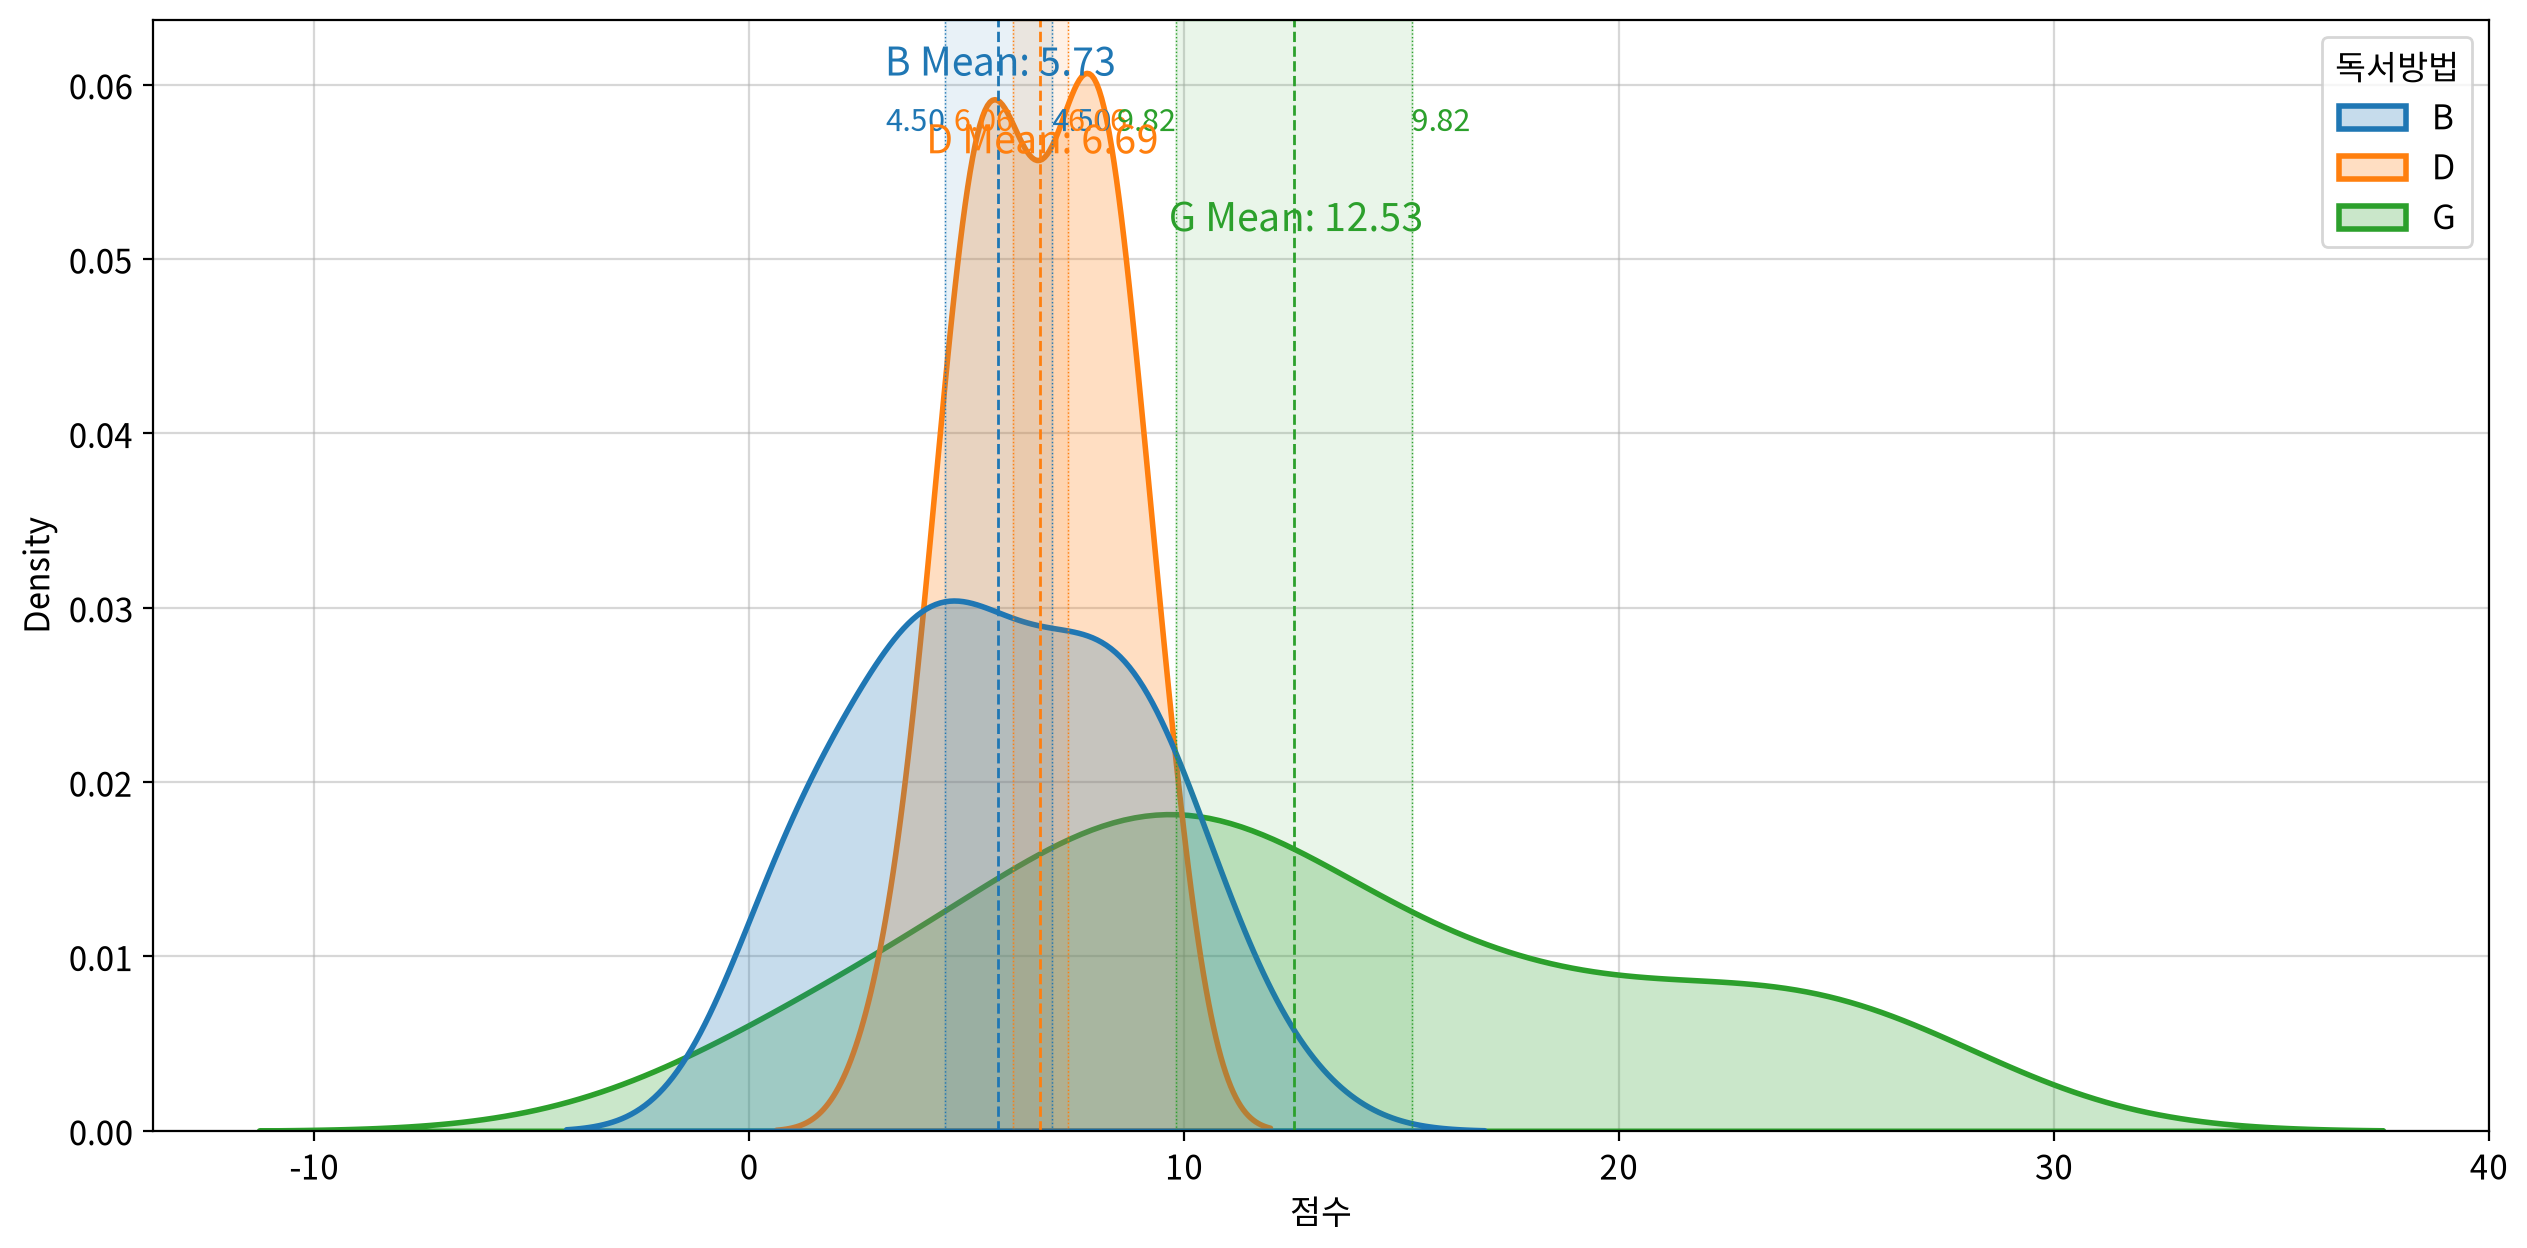

In [15]:
my_plot.kdeplot(df1, x='점수', hue='독서방법', fill=True, meanline=True, clevel=0.95)

In [16]:
# long 타입 데이터로 변환
df1_wide = my_prep.long2wide(df1, hue='독서방법', values='점수')
df1_wide.head()

,B,D,G
0,7.700,9.400,10.600
1,1.500,9.400,9.200
2,4.300,4.400,8.900
3,5.400,3.200,15.700
4,4.300,5.700,0.000


In [17]:
# 가설검정의 가정 확인
my_stats.test_assumptions(df1_wide)

,test,statistic,p-value,result
field,,,,
B,normaltest,2.210,0.331,True
D,normaltest,2.397,0.302,True
G,normaltest,2.217,0.330,True
Bartlett,equal_var,58.099,0.000,False


In [18]:
# 등분산성이 미충족
my_stats.anova_oneway(df1, y='점수', between='독서방법')

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,독서방법,2,48.204,10.787,0.000,0.283,Large


> - 검정 선택: 등분산성을 미충족하여 Welch_anova를 자동 적용
> - 유의성: F(2, 48.204)=10.787, p_unc=0.000 < 0.05 이므로 귀무가설 기각, 세 독서방법 중 적어도 한 방법의 평균 점수는 다르다
> - 효과크기: np2=0.283, effect_size=Large이므로, 독서방법 차이가 점수 변동의 약 28%를 설명, 통계적 유의성을 넘어 실질적으로도 큰 효과

### 문제2

- 서울시에서 정의하는 상권의 종류는 발달상권, 골목상권, 관광특구, 전통시장이 있다.
- commercial 데이터셋은 서울시의 2023년 상권에 따른 분기별 매출액과 매출건수에 대한 자료이다.
- **상권 종류별 2023년 한 해 동안의 평균 매출액**은 어떤 차이가 보이는지 분석하라.
- 주어진 데이터는 서울시에서 제공하는 집계가 완료된 데이터이므로 모든 결측치는 없는 상태이며 이상치도 실제 매출액 데이터이므로 별도의 정제 과정 없이 진행하는 것으로 한다.

In [19]:
# 데이터 불러오기
df2 = load_data('commercial')
df2.head()

📚 서울시의 2023년 상권에 따른 분기별 매출액과 매출건수에 대한 자료 (출처: 서울 열린데이터 광장)


,quarter,code,type,name,sales_amount,number_of_sales
0,1,3001491,관광특구,이태원 관광특구,-490799932,2496865
1,1,3001492,관광특구,명동 남대문 북창동 다동 무교동 관광특구,-135495143,10246122
2,1,3001493,관광특구,동대문패션타운 관광특구,92351597,2880324
3,1,3001494,관광특구,종로·청계 관광특구,1609259121,4960006
4,1,3001495,관광특구,잠실 관광특구,-589847108,5995166


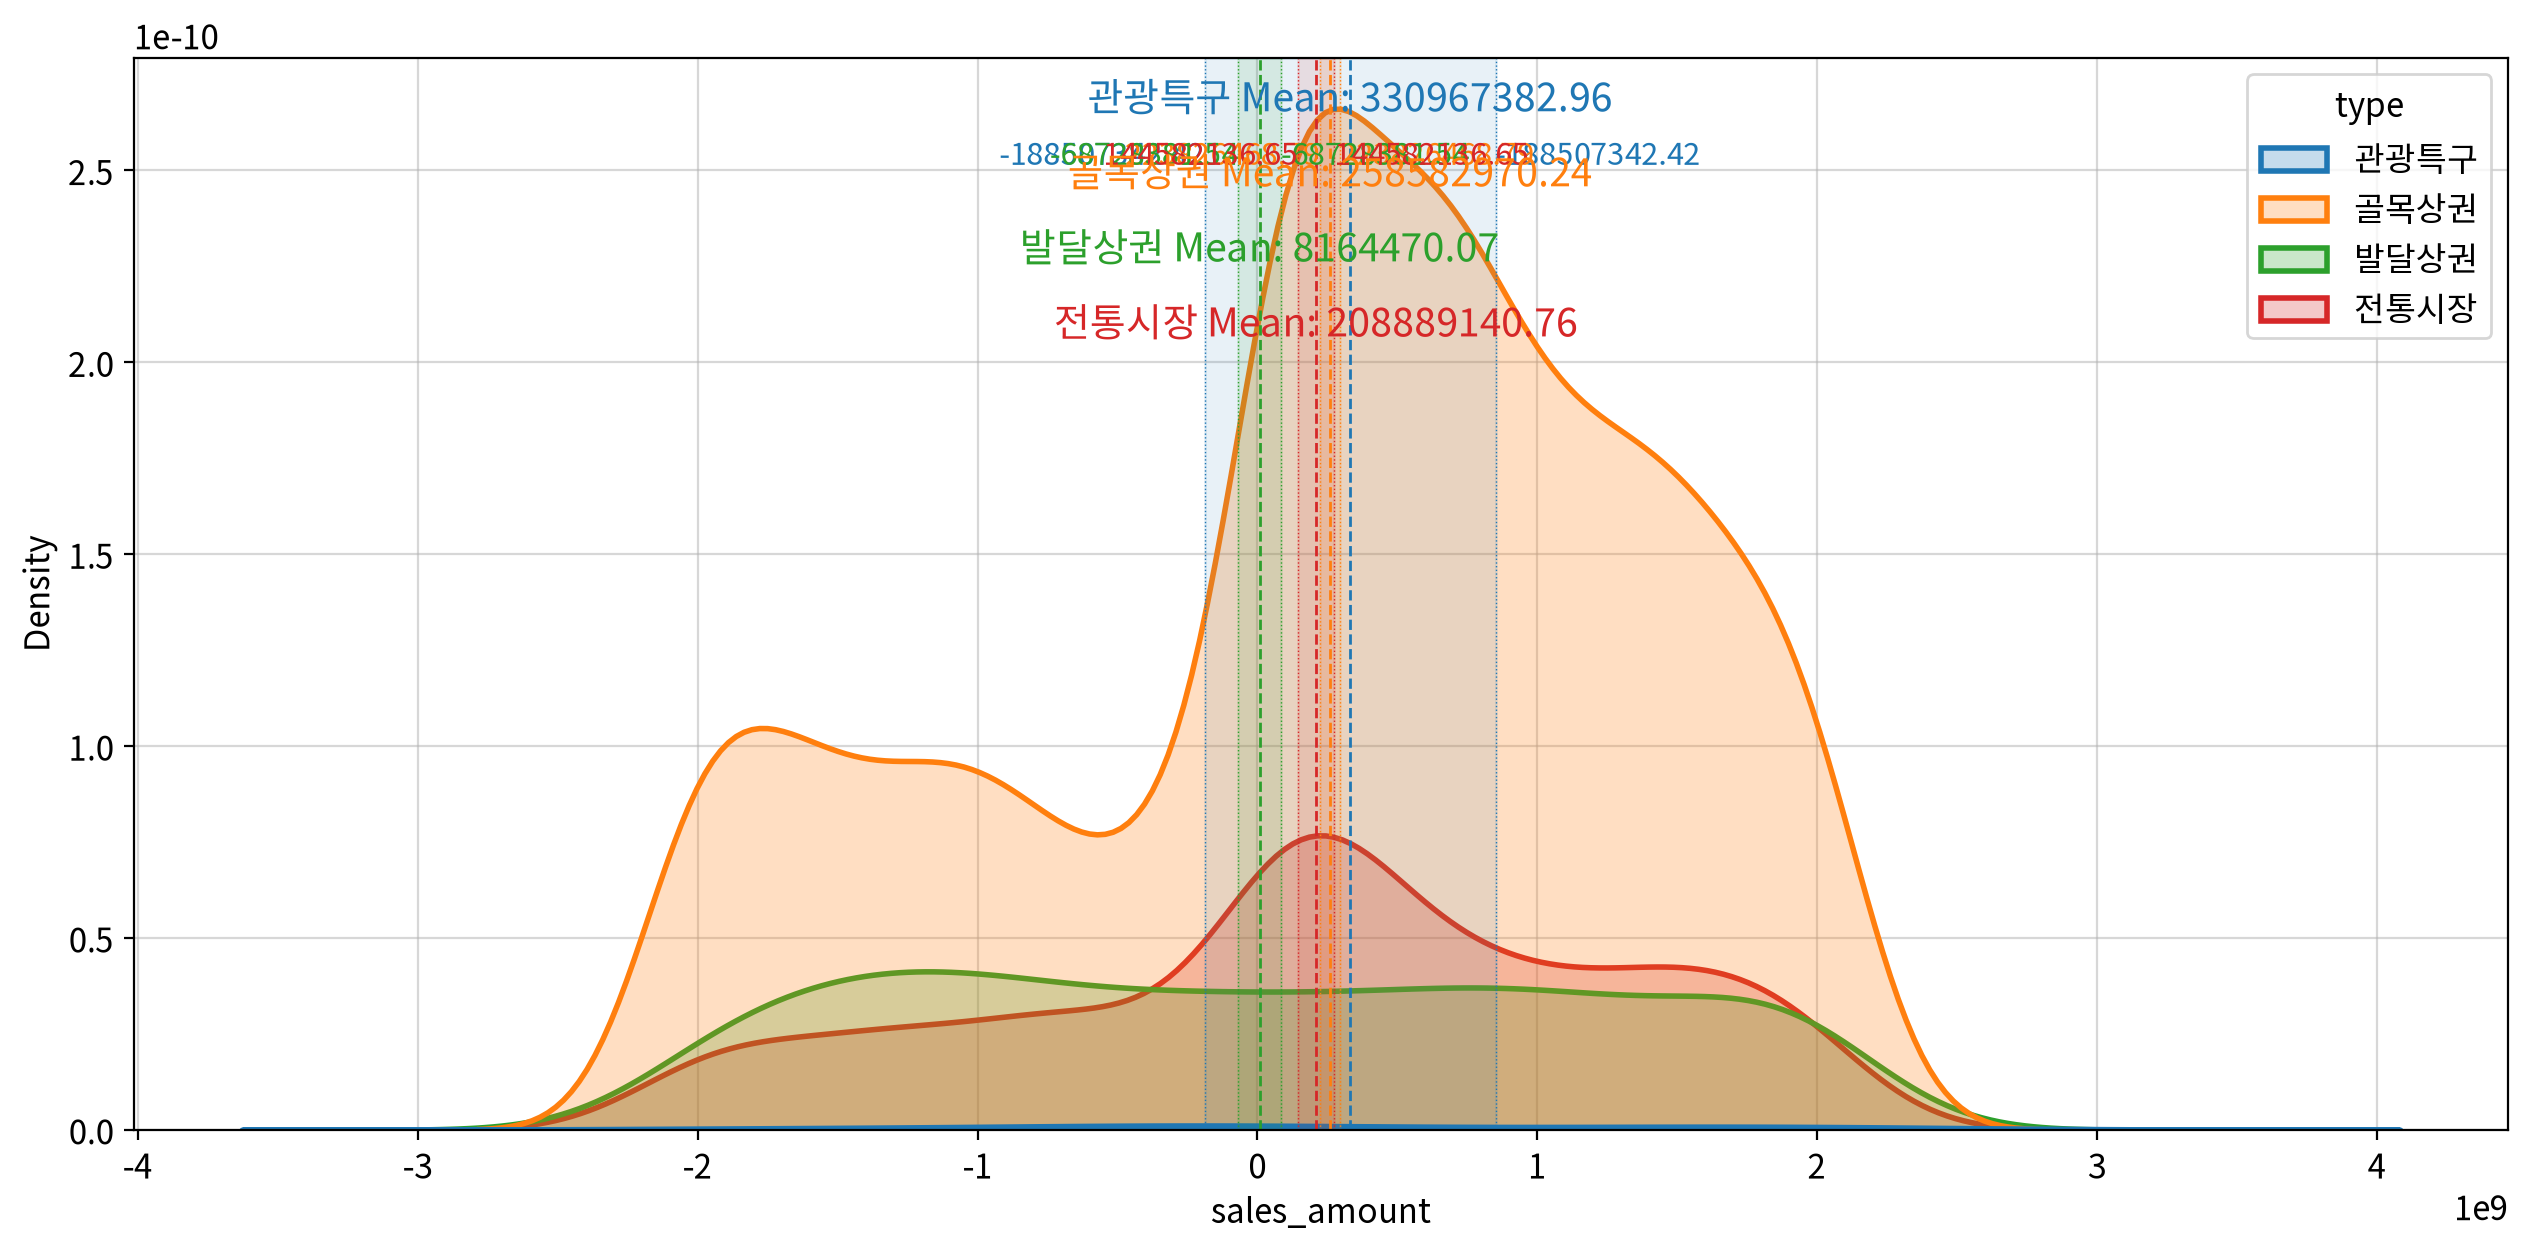

In [20]:
my_plot.kdeplot(df2, x='sales_amount', hue='type', fill=True, meanline=True, clevel=0.95)

In [22]:
my_stats.anova_oneway(df2, y='sales_amount', between='type')

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,type,3,112.227,11.251,0.000,0.006,Negligible


> - 검정 선택: 등분산성을 미충족하여 welch_anova를 자동 적용
> - 유의성: F(3, 1645.152)=74.193, p_unc=0.000 < 0.05 이므로 귀무가설 기각, 네 상권 중 적어도 한 상권의 평균 매출액은 다르다
> - 효과크기: np2=0.006, effect_size=Negligible이므로, 상권의 차이가 평균 매출액 변동의 약 0.6%를 설명, 통계적으로 유의하지만 실질적인 효과는 미미하다